# Praktikum Komputasi Numerik
## Modul 4: Solusi Sistem Persamaan Lanjar (Eliminasi dan Metode Iteratif)

|  |  |
|---|---|
| Nama | Fathin Yassarahman |
| NIM | 241524041 |
| Kelas | 5B |
| Program Studi | D-4 Teknik Informatika |
| Jurusan | Teknik Komputer dan Informatika, Politeknik Negeri Bandung |
| Tanggal | 20 Oktober 2026 |

isi notebook: Task I sampai Task IV, jawaban Tugas Praktikum (III.8), dan Soal Latihan HOTS gaya ICPC (III.9).

sistem uji utama ada dua. sistem 3x3 dari Task I dengan solusi (2, 3, -1) dipakai untuk metode langsung, dan sistem 4x4 Burden-Faires dengan solusi (1, 2, -1, 1) dipakai untuk metode iteratif.

---
# Task 0: Setup Environment

memeriksa python, numpy, dan matplotlib sebelum masuk materi. seluruh perhitungan matriks memakai numpy, dan `np.linalg.solve` hanya dipakai sebagai pembanding

In [1]:
print("Hello, Modul 4!")

import sys
print("Python version:", sys.version.split()[0])

import math
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
print("NumPy version     :", np.__version__)
print("Matplotlib version:", matplotlib.__version__)

Hello, Modul 4!
Python version: 3.13.18


NumPy version     : 2.5.3
Matplotlib version: 3.11.2


---
# Task I: Eliminasi Gauss dengan Pivoting

sistem diubah menjadi segitiga atas dengan operasi baris elementer lalu diselesaikan dengan substitusi mundur. pivoting parsial bisa dimatikan lewat parameter `pivot` supaya bisa dipakai lagi di Tugas 3 dan Problem A

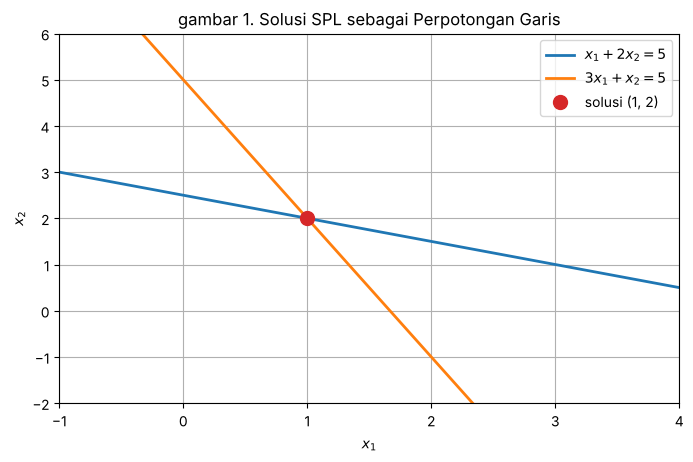

cek np.linalg.solve: [1. 2.]


In [2]:
# I.1 gambar 1. solusi SPL 2x2 sebagai perpotongan dua garis
x = np.linspace(-1, 4, 200)
plt.figure(figsize=(8, 4.8))
plt.plot(x, (5 - x) / 2, lw=2, label="$x_1 + 2x_2 = 5$")
plt.plot(x, 5 - 3 * x, lw=2, label="$3x_1 + x_2 = 5$")
plt.plot([1], [2], "o", ms=10, color="tab:red", label="solusi (1, 2)")
plt.xlim(-1, 4)
plt.ylim(-2, 6)
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title("gambar 1. Solusi SPL sebagai Perpotongan Garis")
plt.legend()
plt.grid(True)
plt.show()

print("cek np.linalg.solve:", np.linalg.solve([[1., 2.], [3., 1.]], [5., 5.]))

In [3]:
# I.2 eliminasi Gauss dengan pivoting parsial dan substitusi mundur
def gauss_elim(A, b, pivot=True, verbose=False):
    """mengembalikan solusi x. pivot=False mematikan penukaran baris."""
    A = np.array(A, dtype=float)
    b = np.array(b, dtype=float)
    n = len(b)
    for k in range(n - 1):                          # eliminasi maju
        if pivot:
            p = np.argmax(np.abs(A[k:, k])) + k     # baris dengan |a_ik| terbesar
            if p != k:
                A[[k, p]] = A[[p, k]]
                b[[k, p]] = b[[p, k]]
                if verbose:
                    print(f"  tukar baris {k} <-> {p}")
        for i in range(k + 1, n):
            m = A[i, k] / A[k, k]                   # faktor eliminasi
            if verbose:
                print(f"  k={k} i={i} m = {m:+.4f}")
            A[i, k:] -= m * A[k, k:]
            b[i] -= m * b[k]
    x = np.zeros(n)                                 # substitusi mundur
    for i in range(n - 1, -1, -1):
        x[i] = (b[i] - A[i, i + 1:] @ x[i + 1:]) / A[i, i]
    return x

A = np.array([[ 2.,  1., -1.],
              [-3., -1.,  2.],
              [-2.,  1.,  2.]])
b = np.array([8., -11., -3.])

print("dengan pivoting:")
x = gauss_elim(A, b, verbose=True)
print("solusi              =", x)
print("cek np.linalg.solve =", np.linalg.solve(A, b))
print("residual ||Ax - b|| =", np.linalg.norm(A @ x - b, np.inf))
print()
print("tanpa pivoting:")
x_np = gauss_elim(A, b, pivot=False, verbose=True)
print("solusi              =", x_np)
print("residual ||Ax - b|| =", np.linalg.norm(A @ x_np - b, np.inf))

dengan pivoting:
  tukar baris 0 <-> 1
  k=0 i=1 m = -0.6667
  k=0 i=2 m = +0.6667
  tukar baris 1 <-> 2
  k=1 i=2 m = +0.2000
solusi              = [ 2.  3. -1.]
cek np.linalg.solve = [ 2.  3. -1.]
residual ||Ax - b|| = 8.881784197001252e-16

tanpa pivoting:
  k=0 i=1 m = -1.5000
  k=0 i=2 m = -1.0000
  k=1 i=2 m = +4.0000
solusi              = [ 2.  3. -1.]
residual ||Ax - b|| = 0.0


U =
[[-3.     -1.      2.    ]
 [ 0.      1.6667  0.6667]
 [ 0.      0.      0.2   ]]
c = [-11.       4.3333  -0.2   ]
det A dari hasil kali diagonal U (dua kali tukar, tanda tetap): -0.9999999999999993
det A dari numpy                                           : -1.0


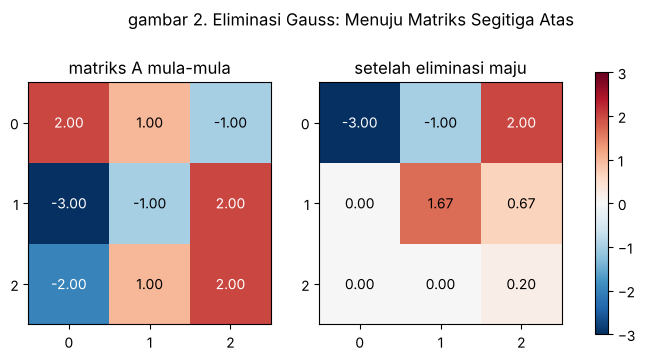

In [4]:
# I.3 gambar 2. matriks sebelum dan sesudah eliminasi maju
def segitiga_atas(A, b):
    """eliminasi maju dengan pivoting, mengembalikan (U, c)."""
    U = np.array(A, dtype=float)
    c = np.array(b, dtype=float)
    n = len(c)
    for k in range(n - 1):
        p = np.argmax(np.abs(U[k:, k])) + k
        U[[k, p]] = U[[p, k]]
        c[[k, p]] = c[[p, k]]
        for i in range(k + 1, n):
            m = U[i, k] / U[k, k]
            U[i, k:] -= m * U[k, k:]
            c[i] -= m * c[k]
    return U, c

U, c = segitiga_atas(A, b)
print("U =")
print(np.round(U, 4))
print("c =", np.round(c, 4))
print("det A dari hasil kali diagonal U (dua kali tukar, tanda tetap):", np.prod(np.diag(U)))
print("det A dari numpy                                           :", np.linalg.det(A))

fig, axes = plt.subplots(1, 2, figsize=(8.6, 4))
batas = np.abs(np.concatenate([A.ravel(), U.ravel()])).max()
for ax, M, judul in [(axes[0], A, "matriks A mula-mula"), (axes[1], U, "setelah eliminasi maju")]:
    im = ax.imshow(M, cmap="RdBu_r", vmin=-batas, vmax=batas)
    for i in range(3):
        for j in range(3):
            warna = "white" if abs(M[i, j]) > 0.6 * batas else "black"
            ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=10, color=warna)
    ax.set_title(judul)
    ax.set_xticks(range(3))
    ax.set_yticks(range(3))
fig.colorbar(im, ax=axes, shrink=0.85)
fig.suptitle("gambar 2. Eliminasi Gauss: Menuju Matriks Segitiga Atas")
plt.show()

In [5]:
# I.4 pengaruh pivoting pada sistem acak: ukuran faktor eliminasi dan galat solusi
rng = np.random.default_rng(4)

def gauss_elim_mmax(A, b, pivot=True):
    """sama seperti gauss_elim, tetapi juga mengembalikan |m| terbesar."""
    A = np.array(A, dtype=float)
    b = np.array(b, dtype=float)
    n = len(b)
    mmax = 0.0
    for k in range(n - 1):
        if pivot:
            p = np.argmax(np.abs(A[k:, k])) + k
            A[[k, p]] = A[[p, k]]
            b[[k, p]] = b[[p, k]]
        for i in range(k + 1, n):
            m = A[i, k] / A[k, k]
            mmax = max(mmax, abs(m))
            A[i, k:] -= m * A[k, k:]
            b[i] -= m * b[k]
    x = np.zeros(n)
    for i in range(n - 1, -1, -1):
        x[i] = (b[i] - A[i, i + 1:] @ x[i + 1:]) / A[i, i]
    return x, mmax

print(f"{'n':>4}{'|m| max tanpa':>16}{'galat tanpa':>14}{'|m| max dengan':>17}{'galat dengan':>15}")
for n in [5, 20, 50, 100]:
    M = rng.uniform(-1, 1, (n, n))
    x_true = np.ones(n)
    rhs = M @ x_true
    x0, m0 = gauss_elim_mmax(M, rhs, pivot=False)
    x1, m1 = gauss_elim_mmax(M, rhs, pivot=True)
    print(f"{n:>4}{m0:>16.3e}{np.abs(x0 - 1).max():>14.3e}{m1:>17.3e}{np.abs(x1 - 1).max():>15.3e}")

   n   |m| max tanpa   galat tanpa   |m| max dengan   galat dengan
   5       1.659e+00     1.221e-15        9.630e-01      7.772e-16
  20       7.642e+01     2.248e-13        9.730e-01      1.776e-15
  50       1.122e+02     1.704e-13        9.970e-01      2.276e-14


 100       2.241e+02     1.039e-11        9.981e-01      1.008e-13


### lesson learnt task I

1. dengan pivoting, program menukar baris dua kali. pada kolom pertama |a11| = 2 kalah dari |-3| di baris kedua, dan setelah kolom pertama dibersihkan, elemen kolom kedua di baris ketiga (1.6667) lebih besar dari baris kedua (0.3333). solusinya (2, 3, -1), sama dengan `np.linalg.solve`, dengan residual 8.88e-16

2. tanpa pivoting, sistem yang sama juga selesai dengan benar dan residualnya malah 0.0. perbedaannya ada di faktor eliminasi: tanpa pivoting nilainya -1.5, -1.0, dan 4.0, sedangkan dengan pivoting semuanya |m| <= 1 (0.6667, 0.6667, 0.2000). pada sistem kecil berangka bulat, manfaat pivoting belum terlihat di hasil akhir

3. manfaatnya baru tampak pada percobaan matriks acak di I.4. tanpa pivoting, |m| terbesar tumbuh menjadi 76.4 pada n = 20 dan 224 pada n = 100, dan galat solusinya 1.04e-11 pada n = 100. dengan pivoting |m| tidak pernah melewati 1 (paling besar 0.998) dan galatnya 1.01e-13, sekitar 100 kali lebih kecil. faktor m yang besar memperbesar galat pembulatan setiap kali baris pivot dikurangkan, sehingga membatasi |m| <= 1 adalah inti kestabilan pivoting. Soal 3 memperlihatkan versi ekstremnya

4. pada gambar 2, diagonal U adalah -3, 1.6667, dan 0.2, sedangkan elemen di bawah diagonal sudah nol. hasil kali diagonal itu -0.9999999999999993, sama dengan det A = -1 dari numpy. karena ada dua kali tukar baris, tandanya tidak berubah. jadi eliminasi Gauss sekaligus memberi determinan tanpa biaya tambahan

---
# Task II: Gauss-Jordan dan Matriks Invers

eliminasi diteruskan sampai matriks koefisien menjadi identitas, sehingga solusi terbaca langsung di kolom terakhir. jalur yang sama dipakai untuk menghitung A^-1, lalu dibandingkan biayanya dengan eliminasi Gauss

In [6]:
# II.1 Gauss-Jordan sampai bentuk eselon baris tereduksi
def gauss_jordan(A, B):
    """menyelesaikan A X = B. B boleh vektor atau matriks (banyak ruas kanan sekaligus)."""
    A = np.array(A, dtype=float)
    B = np.array(B, dtype=float)
    vektor = B.ndim == 1
    M = np.hstack([A, B.reshape(len(A), -1)])
    n = len(A)
    for k in range(n):
        p = np.argmax(np.abs(M[k:, k])) + k
        M[[k, p]] = M[[p, k]]
        M[k] = M[k] / M[k, k]                    # pivot menjadi 1
        for i in range(n):
            if i != k:
                M[i] -= M[i, k] * M[k]           # nolkan kolom k di atas dan di bawah pivot
    X = M[:, n:]
    return X.ravel() if vektor else X

x = gauss_jordan(A, b)
print("solusi Gauss-Jordan =", x)
print("solusi Gauss        =", gauss_elim(A, b))

solusi Gauss-Jordan = [ 2.  3. -1.]
solusi Gauss        = [ 2.  3. -1.]


In [7]:
# II.2 invers lewat Gauss-Jordan pada [A | I]
A_inv = gauss_jordan(A, np.eye(3))
print("invers A (Gauss-Jordan):")
print(np.round(A_inv, 10))
print("invers A (np.linalg.inv):")
print(np.linalg.inv(A))
print("A @ A_inv =")
print(np.round(A @ A_inv, 12))
print("x = A_inv @ b =", A_inv @ b)

invers A (Gauss-Jordan):
[[ 4.  3. -1.]
 [-2. -2.  1.]
 [ 5.  4. -1.]]
invers A (np.linalg.inv):
[[ 4.  3. -1.]
 [-2. -2.  1.]
 [ 5.  4. -1.]]
A @ A_inv =
[[ 1.  0.  0.]
 [ 0.  1. -0.]
 [ 0.  0.  1.]]
x = A_inv @ b = [ 2.  3. -1.]


In [8]:
# II.3 biaya: hitung jumlah perkalian dan pembagian pada tiap jalur
def flop_gauss(n):
    ops = 0
    for k in range(n - 1):
        for i in range(k + 1, n):
            ops += 1 + (n - k) + 1                  # faktor m, baris A, elemen b
    ops += n * (n + 1) // 2                         # substitusi mundur
    return ops

def flop_gauss_jordan(n, kolom_kanan=1):
    lebar = n + kolom_kanan
    ops = 0
    for k in range(n):
        ops += lebar - k                            # normalisasi baris pivot
        ops += (n - 1) * (lebar - k)                # eliminasi baris lain
    return ops

def flop_invers_lalu_kali(n):
    return flop_gauss_jordan(n, kolom_kanan=n) + n * n   # bentuk A^-1 lalu A^-1 b

print(f"{'n':>5}{'Gauss':>14}{'Gauss-Jordan':>15}{'invers + kali':>16}{'rasio inv/Gauss':>17}{'n^3/3':>12}")
for n in [3, 10, 50, 100, 500]:
    g = flop_gauss(n)
    gj = flop_gauss_jordan(n)
    iv = flop_invers_lalu_kali(n)
    print(f"{n:>5}{g:>14}{gj:>15}{iv:>16}{iv / g:>17.2f}{n**3 / 3:>12.0f}")

    n         Gauss   Gauss-Jordan   invers + kali  rasio inv/Gauss       n^3/3
    3            20             27              54             2.70           9
   10           475            650            1650             3.47         333
   50         45375          66250          191250             4.21       41667
  100        348250         515000         1515000             4.35      333333
  500      42041250       62875000       187875000             4.47    41666667


In [9]:
# II.4 akurasi: solve dibanding invers eksplisit pada matriks yang berkondisi buruk
print(f"{'n':>3}{'cond(H)':>11}{'galat solve':>14}{'galat inv @ b':>16}{'residual solve':>17}{'residual inv':>15}")
for n in [6, 8, 10, 12]:
    H = np.array([[1 / (i + j + 1) for j in range(n)] for i in range(n)])
    x_true = np.ones(n)
    rhs = H @ x_true
    x_s = np.linalg.solve(H, rhs)
    x_i = np.linalg.inv(H) @ rhs
    print(f"{n:>3}{np.linalg.cond(H):>11.2e}{np.abs(x_s - 1).max():>14.2e}{np.abs(x_i - 1).max():>16.2e}"
          f"{np.abs(H @ x_s - rhs).max():>17.2e}{np.abs(H @ x_i - rhs).max():>15.2e}")

  n    cond(H)   galat solve   galat inv @ b   residual solve   residual inv
  6   1.50e+07      6.65e-11        1.98e-09         4.44e-16       2.61e-11
  8   1.53e+10      1.31e-07        9.54e-07         4.44e-16       4.97e-08
 10   1.60e+13      2.43e-05        4.91e-03         4.44e-16       9.69e-05
 12   1.62e+16      2.76e-01        5.73e+00         4.44e-16       1.16e-01


### lesson learnt task II

1. Gauss-Jordan memberi solusi (2, 3, -1) yang sama dengan eliminasi Gauss. fungsi `gauss_jordan` saya buat menerima matriks di ruas kanan, sehingga A^-1 diperoleh dalam satu kali jalan pada [A | I]. hasilnya [[4, 3, -1], [-2, -2, 1], [5, 4, -1]], sama dengan `np.linalg.inv`, dan A @ A_inv menghasilkan matriks identitas

2. hitungan jumlah perkalian dan pembagian di II.3 menjawab pertanyaan biaya. untuk n = 500, Gauss butuh 42.0 juta operasi (sangat dekat dengan n^3/3 = 41.7 juta), Gauss-Jordan 62.9 juta, dan jalur "bentuk A^-1 lalu kalikan b" 187.9 juta, yaitu 4.47 kali Gauss. versi saya tidak memanfaatkan nol pada matriks identitas; dengan memanfaatkannya rasionya turun ke sekitar 3, sesuai petunjuk modul. dalam dua hitungan itu invers tetap paling mahal

3. dari sisi akurasi, pada matriks Hilbert n = 10 galat `solve` 2.43e-05 sedangkan galat `inv @ b` 4.91e-03, sekitar 200 kali lebih buruk. residual `solve` tetap 4.44e-16 untuk semua n, sedangkan residual jalur invers membesar sampai 1.16e-01 pada n = 12. jadi menghitung invers secara eksplisit lebih mahal dan juga kurang akurat. invers baru layak dihitung bila memang isinya yang dibutuhkan, dan Gauss-Jordan berguna bila ada banyak ruas kanan sekaligus seperti pada [A | I]

---
# Task III: Metode Iteratif Jacobi dan Gauss-Seidel

sistem 4x4 Burden-Faires diselesaikan dengan dua metode iteratif. bedanya hanya satu: Jacobi memakai nilai iterasi lama untuk semua komponen, Gauss-Seidel langsung memakai nilai terbaru

In [10]:
# III.1 sistem 4x4 dan uji dominansi diagonal per baris
A4 = np.array([[10., -1.,  2.,  0.],
               [-1., 11., -1.,  3.],
               [ 2., -1., 10., -1.],
               [ 0.,  3., -1.,  8.]])
b4 = np.array([6., 25., -11., 15.])

def cek_dominan(A, cetak=True):
    """True bila |a_ii| > jumlah |a_ij| (j != i) untuk semua baris."""
    A = np.array(A, dtype=float)
    hasil = []
    for i in range(len(A)):
        off = np.sum(np.abs(A[i])) - abs(A[i, i])
        hasil.append(abs(A[i, i]) > off)
        if cetak:
            print(f"baris {i + 1}: |a_ii| = {abs(A[i, i]):g} > off-diagonal = {off:g} ? {hasil[-1]}")
    return all(hasil)

print("diagonal-dominan:", cek_dominan(A4))

baris 1: |a_ii| = 10 > off-diagonal = 3 ? True
baris 2: |a_ii| = 11 > off-diagonal = 5 ? True
baris 3: |a_ii| = 10 > off-diagonal = 4 ? True
baris 4: |a_ii| = 8 > off-diagonal = 4 ? True
diagonal-dominan: True


In [11]:
# III.2 Jacobi dan Gauss-Seidel, kriteria berhenti ||x_baru - x_lama||_inf < tol
def jacobi(A, b, tol=1e-8, max_iter=100, x0=None, riwayat=False):
    """mengembalikan (x, jumlah iterasi) atau (x, n, daftar x tiap iterasi) bila riwayat=True."""
    A = np.array(A, dtype=float)
    b = np.array(b, dtype=float)
    n = len(b)
    x = np.zeros(n) if x0 is None else np.array(x0, dtype=float)
    jejak = []
    for it in range(1, max_iter + 1):
        x_baru = np.zeros(n)
        for i in range(n):
            s = A[i, :i] @ x[:i] + A[i, i + 1:] @ x[i + 1:]
            x_baru[i] = (b[i] - s) / A[i, i]        # semua memakai x lama
        jejak.append(x_baru.copy())
        selesai = np.linalg.norm(x_baru - x, np.inf) < tol
        x = x_baru
        if selesai:
            return (x, it, jejak) if riwayat else (x, it)
    return (x, max_iter, jejak) if riwayat else (x, max_iter)

def gauss_seidel(A, b, tol=1e-8, max_iter=100, x0=None, riwayat=False):
    A = np.array(A, dtype=float)
    b = np.array(b, dtype=float)
    n = len(b)
    x = np.zeros(n) if x0 is None else np.array(x0, dtype=float)
    jejak = []
    for it in range(1, max_iter + 1):
        x_lama = x.copy()
        for i in range(n):
            s = A[i, :i] @ x[:i] + A[i, i + 1:] @ x[i + 1:]
            x[i] = (b[i] - s) / A[i, i]             # x[:i] sudah nilai terbaru
        jejak.append(x.copy())
        if np.linalg.norm(x - x_lama, np.inf) < tol:
            return (x, it, jejak) if riwayat else (x, it)
    return (x, max_iter, jejak) if riwayat else (x, max_iter)

xj, nj, jejak_j = jacobi(A4, b4, riwayat=True)
xg, ng, jejak_g = gauss_seidel(A4, b4, riwayat=True)
print("jacobi       : x =", xj, " iterasi =", nj)
print("gauss-seidel : x =", xg, " iterasi =", ng)
print("cek          :", np.linalg.solve(A4, b4))

jacobi       : x = [ 1.  2. -1.  1.]  iterasi = 24
gauss-seidel : x = [ 1.  2. -1.  1.]  iterasi = 10
cek          : [ 1.  2. -1.  1.]


In [12]:
# III.3 enam iterasi pertama masing-masing metode
for nama, jejak in [("Jacobi", jejak_j), ("Gauss-Seidel", jejak_g)]:
    print(nama)
    print(f"{'it':>3}{'x1':>11}{'x2':>11}{'x3':>11}{'x4':>11}")
    for k, xk in enumerate(jejak[:6], start=1):
        print(f"{k:>3}" + "".join(f"{v:>11.6f}" for v in xk))
    print()

Jacobi
 it         x1         x2         x3         x4
  1   0.600000   2.272727  -1.100000   1.875000
  2   1.047273   1.715909  -0.805227   0.885227
  3   0.932636   2.053306  -1.049341   1.130881
  4   1.015199   1.953696  -0.968109   0.973843
  5   0.988991   2.011415  -1.010286   1.021351
  6   1.003199   1.992241  -0.994522   0.994434

Gauss-Seidel
 it         x1         x2         x3         x4
  1   0.600000   2.327273  -0.987273   0.878864
  2   1.030182   2.036938  -1.014456   0.984341
  3   1.006585   2.003555  -1.002527   0.998351
  4   1.000861   2.000298  -1.000307   0.999850
  5   1.000091   2.000021  -1.000031   0.999988
  6   1.000008   2.000001  -1.000003   0.999999



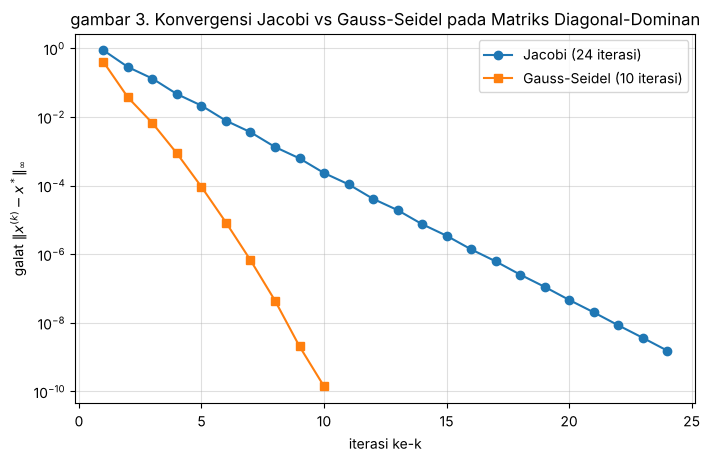

rasio galat Jacobi (iterasi 2..15): [0.325 0.461 0.354 0.461 0.363 0.463 0.37  0.466 0.375 0.468 0.378 0.469
 0.39  0.459]
rasio galat G-S    (iterasi 2..8) : [0.092 0.178 0.131 0.106 0.092 0.08  0.066]


In [13]:
# III.4 gambar 3. galat terhadap solusi eksak per iterasi
x_star = np.array([1., 2., -1., 1.])
err_j = [np.linalg.norm(xk - x_star, np.inf) for xk in jejak_j]
err_g = [np.linalg.norm(xk - x_star, np.inf) for xk in jejak_g]

plt.figure(figsize=(8, 4.8))
plt.semilogy(range(1, len(err_j) + 1), err_j, "o-", label=f"Jacobi ({nj} iterasi)")
plt.semilogy(range(1, len(err_g) + 1), err_g, "s-", label=f"Gauss-Seidel ({ng} iterasi)")
plt.xlabel("iterasi ke-k")
plt.ylabel(r"galat $\|x^{(k)} - x^*\|_\infty$")
plt.title("gambar 3. Konvergensi Jacobi vs Gauss-Seidel pada Matriks Diagonal-Dominan")
plt.legend()
plt.grid(True, which="both", alpha=0.4)
plt.show()

rasio_j = [err_j[k] / err_j[k - 1] for k in range(1, 15)]
rasio_g = [err_g[k] / err_g[k - 1] for k in range(1, 8)]
print("rasio galat Jacobi (iterasi 2..15):", np.round(rasio_j, 3))
print("rasio galat G-S    (iterasi 2..8) :", np.round(rasio_g, 3))

In [14]:
# III.5 radius spektral matriks iterasi menjelaskan laju konvergensi
def radius_spektral(A):
    """kembalikan (rho Jacobi, rho Gauss-Seidel) dari pemecahan A = D + L + U."""
    A = np.array(A, dtype=float)
    D = np.diag(np.diag(A))
    L = np.tril(A, -1)
    U = np.triu(A, 1)
    T_j = -np.linalg.solve(D, L + U)
    T_g = -np.linalg.solve(D + L, U)
    return max(abs(np.linalg.eigvals(T_j))), max(abs(np.linalg.eigvals(T_g)))

rho_j, rho_g = radius_spektral(A4)
print(f"rho(T_jacobi) = {rho_j:.6f}")
print(f"rho(T_gs)     = {rho_g:.6f}")
print(f"rho_j^2       = {rho_j**2:.6f}")
print(f"perkiraan iterasi untuk memangkas galat 1e-8 kali: Jacobi {math.log(1e-8) / math.log(rho_j):.1f}, "
      f"Gauss-Seidel {math.log(1e-8) / math.log(rho_g):.1f}")

rho(T_jacobi) = 0.426437
rho(T_gs)     = 0.089823
rho_j^2       = 0.181848
perkiraan iterasi untuk memangkas galat 1e-8 kali: Jacobi 21.6, Gauss-Seidel 7.6


### lesson learnt task III

1. keempat baris lolos uji dominansi (10 > 3, 11 > 5, 10 > 4, 8 > 4). Jacobi selesai dalam 24 iterasi dan Gauss-Seidel dalam 10 iterasi, keduanya menuju (1, 2, -1, 1). enam baris pertama kedua tabel sama persis dengan Tabel 4 dan Tabel 5 modul

2. pada iterasi ke-6, Gauss-Seidel sudah memberi x1 = 1.000008, sedangkan Jacobi baru 1.003199. dari gambar 3, rasio galat Jacobi bergantian antara sekitar 0.33 dan 0.47, sedangkan rasio Gauss-Seidel berada di 0.07 sampai 0.18. jadi tiap putaran Gauss-Seidel memangkas galat jauh lebih banyak

3. laju itu bisa diprediksi dari radius spektral matriks iterasi: rho(T_J) = 0.426437 dan rho(T_GS) = 0.089823. dengan log(1e-8)/log(rho), perkiraan jumlah iterasinya 21.6 untuk Jacobi dan 7.6 untuk Gauss-Seidel. angka aktual 24 dan 10 sedikit lebih besar, karena galat awal dari x0 = 0 sekitar 2 dan kriteria berhentinya memakai perubahan antar iterasi, bukan galat. di sini rho(T_GS) bahkan lebih kecil dari rho(T_J)^2 = 0.181848, sehingga Gauss-Seidel lebih dari dua kali lebih cepat (24/10 = 2.4)

---
# Task IV: Dominansi Diagonal dan Kestabilan Iterasi

Jacobi dijalankan pada matriks yang sengaja tidak diagonal-dominan, lalu dicari cara menyelamatkannya

In [15]:
# IV.1 Jacobi pada matriks yang tidak diagonal-dominan
A2 = np.array([[1., 2.],
               [3., 1.]])
b2 = np.array([5., 5.])
x_eksak2 = np.linalg.solve(A2, b2)
print("solusi eksak:", x_eksak2)
cek_dominan(A2)

x = np.zeros(2)
errs = []
for it in range(14):
    xb = np.zeros(2)
    for i in range(2):
        s = A2[i, :i] @ x[:i] + A2[i, i + 1:] @ x[i + 1:]
        xb[i] = (b2[i] - s) / A2[i, i]
    x = xb
    errs.append(np.linalg.norm(x - x_eksak2, np.inf))
    if it < 4 or it > 10:
        print(f"iter {it + 1:2d}: x = {x},  ||x - x*|| = {errs[-1]:.3e}")
    elif it == 4:
        print("...")
print("rasio galat berturut-turut:", np.round([errs[k] / errs[k - 1] for k in range(1, 14)], 4))

solusi eksak: [1. 2.]
baris 1: |a_ii| = 1 > off-diagonal = 2 ? False
baris 2: |a_ii| = 1 > off-diagonal = 3 ? False
iter  1: x = [5. 5.],  ||x - x*|| = 4.000e+00
iter  2: x = [ -5. -10.],  ||x - x*|| = 1.200e+01
iter  3: x = [25. 20.],  ||x - x*|| = 2.400e+01
iter  4: x = [-35. -70.],  ||x - x*|| = 7.200e+01
...
iter 12: x = [-46655. -93310.],  ||x - x*|| = 9.331e+04
iter 13: x = [186625. 139970.],  ||x - x*|| = 1.866e+05
iter 14: x = [-279935. -559870.],  ||x - x*|| = 5.599e+05
rasio galat berturut-turut: [3. 2. 3. 2. 3. 2. 3. 2. 3. 2. 3. 2. 3.]


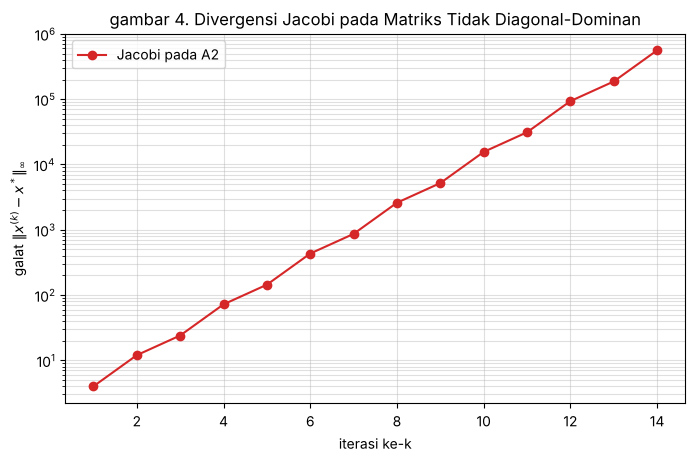

rho(T_jacobi) = 2.449490   (sqrt(6) = 2.449490)
rho(T_gs)     = 6.000000


In [16]:
# IV.2 gambar 4. galat Jacobi membesar tiap putaran
plt.figure(figsize=(8, 4.8))
plt.semilogy(range(1, 15), errs, "o-", color="tab:red", label="Jacobi pada A2")
plt.xlabel("iterasi ke-k")
plt.ylabel(r"galat $\|x^{(k)} - x^*\|_\infty$")
plt.title("gambar 4. Divergensi Jacobi pada Matriks Tidak Diagonal-Dominan")
plt.legend()
plt.grid(True, which="both", alpha=0.4)
plt.show()

rho_j2, rho_g2 = radius_spektral(A2)
print(f"rho(T_jacobi) = {rho_j2:.6f}   (sqrt(6) = {math.sqrt(6):.6f})")
print(f"rho(T_gs)     = {rho_g2:.6f}")

In [17]:
# IV.3 penyelamatan: tukar urutan kedua persamaan supaya diagonal menjadi dominan
A2s = A2[[1, 0]]
b2s = b2[[1, 0]]
print("A2 setelah tukar baris:")
print(A2s)
print("diagonal-dominan:", cek_dominan(A2s, cetak=False))
xj2, nj2 = jacobi(A2s, b2s)
xg2, ng2 = gauss_seidel(A2s, b2s)
print("jacobi       :", xj2, "iterasi", nj2)
print("gauss-seidel :", xg2, "iterasi", ng2)
print("rho jacobi, rho gs setelah tukar:", np.round(radius_spektral(A2s), 6))
print()
print("Gauss-Seidel pada urutan asli juga gagal:")
xg_asli, ng_asli = gauss_seidel(A2, b2, max_iter=10)
print("x setelah 10 iterasi =", xg_asli)

A2 setelah tukar baris:
[[3. 1.]
 [1. 2.]]
diagonal-dominan: True
jacobi       : [1. 2.] iterasi 23
gauss-seidel : [1. 2.] iterasi 12
rho jacobi, rho gs setelah tukar: [0.408248 0.166667]

Gauss-Seidel pada urutan asli juga gagal:
x setelah 10 iterasi = [ 4.0310785e+07 -1.2093235e+08]


### lesson learnt task IV

1. kedua baris A2 gagal uji dominansi (1 lawan 2 dan 1 lawan 3). galat Jacobi naik dari 4 menjadi 12, 24, 72, lalu 5.599e+05 pada iterasi ke-14, sama dengan keluaran modul. rasio galatnya bergantian tepat 3 dan 2, sehingga rata-rata geometrinya sqrt(6) = 2.449490, sama persis dengan rho(T_J). divergensi ini bukan kebetulan: begitu radius spektral lebih dari 1, galat pasti membesar

2. Gauss-Seidel tidak menolong. rho(T_GS) = 6, dan setelah 10 iterasi x sudah (4.03e7, -1.21e8). memakai nilai terbaru justru mempercepat ledakan

3. menukar urutan kedua persamaan menghasilkan [[3, 1], [1, 2]] yang diagonal-dominan. sistem dan solusinya sama, tetapi Jacobi kini konvergen dalam 23 iterasi dan Gauss-Seidel dalam 12, dengan rho 0.408 dan 0.167. jadi sebelum menjalankan metode iteratif, periksa dominansi diagonal dan coba susun ulang persamaannya. bila tidak bisa dibuat dominan, metode langsung Task I tetap bekerja tanpa syarat itu

---
# Kesimpulan Praktikum

| metode | jenis | hasil pada sistem uji | biaya | syarat |
|---|---|---|---|---|
| Gauss + pivoting | langsung | (2, 3, -1), residual 8.9e-16 | sekitar n^3/3 (42.0 juta pada n = 500) | pivot tidak nol, pivoting menjaga \|m\| <= 1 |
| Gauss-Jordan | langsung | (2, 3, -1), invers sama dengan numpy | sekitar 1.5 kali Gauss (62.9 juta pada n = 500) | sama dengan Gauss |
| Jacobi | iteratif | 24 iterasi pada sistem 4x4 | sekitar n^2 per iterasi | rho(T_J) < 1, dijamin bila diagonal-dominan |
| Gauss-Seidel | iteratif | 10 iterasi pada sistem 4x4 | sekitar n^2 per iterasi | rho(T_GS) < 1, dijamin bila diagonal-dominan |

temuan dari keempat task:

1. metode langsung memberi solusi dalam jumlah langkah pasti. pivoting tidak mengubah hasil pada sistem 3x3 berangka bulat, tetapi pada matriks acak n = 100 galatnya turun dari 1.04e-11 ke 1.01e-13 karena faktor eliminasi dijaga tidak lebih dari 1
2. invers eksplisit kalah di dua sisi: 4.47 kali lebih mahal dari Gauss pada n = 500 dalam hitungan saya, dan pada Hilbert n = 10 galatnya 200 kali lebih besar dari `np.linalg.solve`
3. laju metode iteratif ditentukan radius spektral matriks iterasinya. pada sistem 4x4, rho 0.4264 dan 0.0898 menjelaskan mengapa Gauss-Seidel butuh 10 iterasi dan Jacobi 24
4. tanpa dominansi diagonal, iterasi bisa meledak dengan laju yang juga bisa dihitung (sqrt(6) per iterasi pada A2). menukar urutan persamaan cukup untuk menyelamatkannya

---
---
# BAGIAN III.8 - Tugas Praktikum

## Soal 1. Sistem 3x3

selesaikan 3x1 + 2x2 + x3 = 10, x1 + 4x2 + 2x3 = 12, 2x1 + x2 + 5x3 = 15 dengan eliminasi Gauss dan Jacobi (toleransi 1e-8), lalu laporkan jumlah iterasi Jacobi beserta penyebab konvergensinya relatif lambat

In [18]:
# Soal 1. Gauss dan Jacobi pada sistem 3x3
S1 = np.array([[3., 2., 1.],
               [1., 4., 2.],
               [2., 1., 5.]])
c1 = np.array([10., 12., 15.])

x_gauss = gauss_elim(S1, c1)
x_jac, n_jac = jacobi(S1, c1, tol=1e-8, max_iter=500)
print("Gauss  :", x_gauss)
print("Jacobi :", x_jac, " iterasi =", n_jac)
print("solve  :", np.linalg.solve(S1, c1))
print()
cek_dominan(S1)
rj, rg = radius_spektral(S1)
print(f"rho(T_jacobi) = {rj:.6f},  rho(T_gs) = {rg:.6f}")
print(f"perkiraan iterasi Jacobi: log(1e-8)/log(rho) = {math.log(1e-8) / math.log(rj):.1f}")
x_gs1, n_gs1 = gauss_seidel(S1, c1, tol=1e-8, max_iter=500)
print("Gauss-Seidel sebagai pembanding: iterasi =", n_gs1)

Gauss  : [1.6        1.57777778 2.04444444]
Jacobi : [1.6        1.57777778 2.04444445]  iterasi = 77
solve  : [1.6        1.57777778 2.04444444]

baris 1: |a_ii| = 3 > off-diagonal = 3 ? False
baris 2: |a_ii| = 4 > off-diagonal = 3 ? True
baris 3: |a_ii| = 5 > off-diagonal = 3 ? True
rho(T_jacobi) = 0.771062,  rho(T_gs) = 0.365148
perkiraan iterasi Jacobi: log(1e-8)/log(rho) = 70.9
Gauss-Seidel sebagai pembanding: iterasi = 21


### jawaban soal 1

| metode | x1 | x2 | x3 | iterasi |
|---|---|---|---|---|
| eliminasi Gauss | 1.6 | 1.57777778 | 2.04444444 | langsung |
| Jacobi (tol 1e-8) | 1.6 | 1.57777778 | 2.04444445 | 77 |

solusi eksaknya (72/45, 71/45, 92/45). Jacobi butuh 77 iterasi, lebih dari tiga kali sistem 4x4 di Task III. penyebabnya terlihat dari uji dominansi: baris pertama tidak dominan ketat (3 lawan 2 + 1 = 3), dan dua baris lainnya hanya menang tipis (4 lawan 3, 5 lawan 3). akibatnya rho(T_J) = 0.771062, sehingga tiap iterasi hanya memangkas galat sekitar 23 persen. perkiraan log(1e-8)/log(0.771) = 70.9 iterasi sudah dekat dengan 77.

Jacobi tetap konvergen karena rho < 1. dominansi diagonal adalah syarat cukup, bukan syarat perlu. Gauss-Seidel pada sistem yang sama hanya butuh 21 iterasi (rho = 0.365).

## Soal 2. Analisis nodal rangkaian listrik

4V1 - V2 = 15, -V1 + 4V2 - V3 = 10, -V2 + 4V3 = 10. selesaikan dengan Jacobi dan Gauss-Seidel (toleransi 1e-8), laporkan V1, V2, V3, jumlah iterasi masing-masing, dan bandingkan kecepatannya

In [19]:
# Soal 2. tiga node, Jacobi dan Gauss-Seidel
S2 = np.array([[ 4., -1.,  0.],
               [-1.,  4., -1.],
               [ 0., -1.,  4.]])
c2 = np.array([15., 10., 10.])

vj, nvj = jacobi(S2, c2, tol=1e-8)
vg, nvg = gauss_seidel(S2, c2, tol=1e-8)
print(f"Jacobi       : V1 = {vj[0]:.6f}, V2 = {vj[1]:.6f}, V3 = {vj[2]:.6f}  iterasi = {nvj}")
print(f"Gauss-Seidel : V1 = {vg[0]:.6f}, V2 = {vg[1]:.6f}, V3 = {vg[2]:.6f}  iterasi = {nvg}")
print("solve        :", np.linalg.solve(S2, c2))
print("pecahan eksak: V1 = 275/56 =", 275 / 56, ", V2 = 65/14 =", 65 / 14, ", V3 = 205/56 =", 205 / 56)
rj, rg = radius_spektral(S2)
print(f"rho jacobi = {rj:.6f} (= sqrt(2)/4 = {math.sqrt(2) / 4:.6f}),  rho gs = {rg:.6f} (= 1/8)")

Jacobi       : V1 = 4.910714, V2 = 4.642857, V3 = 3.660714  iterasi = 21
Gauss-Seidel : V1 = 4.910714, V2 = 4.642857, V3 = 3.660714  iterasi = 12
solve        : [4.91071429 4.64285714 3.66071429]
pecahan eksak: V1 = 275/56 = 4.910714285714286 , V2 = 65/14 = 4.642857142857143 , V3 = 205/56 = 3.6607142857142856
rho jacobi = 0.353553 (= sqrt(2)/4 = 0.353553),  rho gs = 0.125000 (= 1/8)


### jawaban soal 2

| metode | V1 | V2 | V3 | iterasi |
|---|---|---|---|---|
| Jacobi | 4.910714 | 4.642857 | 3.660714 | 21 |
| Gauss-Seidel | 4.910714 | 4.642857 | 3.660714 | 12 |

nilai eksaknya V1 = 275/56, V2 = 65/14, dan V3 = 205/56. Gauss-Seidel menyelesaikannya dengan 9 iterasi lebih sedikit, sekitar 1.75 kali lebih cepat.

matriks tridiagonal ini memberi rho(T_J) = sqrt(2)/4 = 0.353553 dan rho(T_GS) = 1/8 = 0.125, tepat kuadrat dari rho Jacobi. pada matriks tridiagonal seperti ini, satu iterasi Gauss-Seidel setara dengan dua iterasi Jacobi. rasio jumlah iterasinya belum tepat 2 karena kriteria berhentinya memakai perubahan antar iterasi; Problem C menunjukkan rasio itu mendekati 2 bila toleransinya diperketat.

## Soal 3. Pivoting menyelamatkan

1e-20 x1 + x2 = 1 dan x1 + x2 = 2. selesaikan dengan eliminasi Gauss tanpa pivoting dan dengan pivoting, bandingkan dengan solusi eksak (1, 1), dan jelaskan penyebab perbedaannya

In [20]:
# Soal 3. pivot kecil 1e-20
eps = 1e-20
S3 = np.array([[eps, 1.],
               [1.,  1.]])
c3 = np.array([1., 2.])

print("tanpa pivoting:")
x_tanpa = gauss_elim(S3, c3, pivot=False, verbose=True)
print("  x =", x_tanpa)
print("dengan pivoting:")
x_dengan = gauss_elim(S3, c3, pivot=True, verbose=True)
print("  x =", x_dengan)
print()
x_eksak = np.array([1 / (1 - eps), (1 - 2 * eps) / (1 - eps)])
print("solusi eksak (dibulatkan ke float):", x_eksak)
print()
m = 1 / eps
print("jejak langkah tanpa pivoting:")
print(f"  m = 1/eps                 = {m:.1e}")
print(f"  a22 = 1 - m * 1           = {1 - m:.17e}")
print(f"  b2  = 2 - m * 1           = {2 - m:.17e}")
print(f"  x2  = b2 / a22            = {(2 - m) / (1 - m):.17f}")
print(f"  x1  = (1 - x2) / eps      = {(1 - (2 - m) / (1 - m)) / eps}")
print(f"  apakah 1e20 - 2 == 1e20 - 1 dalam float? {1e20 - 2 == 1e20 - 1}")

tanpa pivoting:
  k=0 i=1 m = +100000000000000000000.0000
  x = [0. 1.]
dengan pivoting:
  tukar baris 0 <-> 1
  k=0 i=1 m = +0.0000
  x = [1. 1.]

solusi eksak (dibulatkan ke float): [1. 1.]

jejak langkah tanpa pivoting:
  m = 1/eps                 = 1.0e+20
  a22 = 1 - m * 1           = -1.00000000000000000e+20
  b2  = 2 - m * 1           = -1.00000000000000000e+20
  x2  = b2 / a22            = 1.00000000000000000
  x1  = (1 - x2) / eps      = 0.0
  apakah 1e20 - 2 == 1e20 - 1 dalam float? True


### jawaban soal 3

| cara | x1 | x2 |
|---|---|---|
| tanpa pivoting | 0.0 | 1.0 |
| dengan pivoting | 1.0 | 1.0 |
| eksak | 1/(1 - 1e-20), dibulatkan 1.0 | (1 - 2e-20)/(1 - 1e-20), dibulatkan 1.0 |

tanpa pivoting, x1 meleset 100 persen. jejak langkahnya menunjukkan penyebabnya. faktor m = 1e20, sehingga a22 = 1 - 1e20 dan b2 = 2 - 1e20 sama-sama dibulatkan menjadi -1e20. jarak antar float di sekitar 1e20 adalah 16384, jadi angka 1 dan 2 di persamaan kedua hilang seluruhnya, dan `1e20 - 2 == 1e20 - 1` bernilai True. akibatnya x2 = 1 tepat, lalu x1 = (1 - x2)/1e-20 = 0. nilai x2 sebenarnya hanya selisih 1e-20 dari 1, tetapi selisih sekecil itu dibagi 1e-20 lagi saat substitusi mundur.

dengan pivoting, baris x1 + x2 = 2 naik menjadi pivot dan faktornya m = 1e-20. semua angka yang dikurangkan tetap berorde 1, sehingga tidak ada informasi yang hilang.

## Soal 4. Sistem 4x4 dari model jaringan

5x1 + x2 - x3 = 10, 2x1 + 6x2 + x4 = 12, -x1 + 7x3 + x4 = 14, x2 + 2x3 + 8x4 = 16. selesaikan dengan Gauss-Seidel, cek dominansi diagonal terlebih dahulu, dan verifikasi dengan `np.linalg.solve`

In [21]:
# Soal 4. Gauss-Seidel pada jaringan 4x4
S4 = np.array([[ 5., 1., -1., 0.],
               [ 2., 6.,  0., 1.],
               [-1., 0.,  7., 1.],
               [ 0., 1.,  2., 8.]])
c4 = np.array([10., 12., 14., 16.])

print("diagonal-dominan:", cek_dominan(S4))
x4, n4, jejak4 = gauss_seidel(S4, c4, tol=1e-8, riwayat=True)
x4_solve = np.linalg.solve(S4, c4)
print("Gauss-Seidel :", np.round(x4, 8), " iterasi =", n4)
print("solve        :", np.round(x4_solve, 8))
print("selisih maks :", np.abs(x4 - x4_solve).max())
print("residual     :", np.abs(S4 @ x4 - c4).max())
x4j, n4j = jacobi(S4, c4, tol=1e-8)
print("Jacobi sebagai pembanding: iterasi =", n4j)
print("rho jacobi, rho gs:", np.round(radius_spektral(S4), 6))

baris 1: |a_ii| = 5 > off-diagonal = 2 ? True
baris 2: |a_ii| = 6 > off-diagonal = 3 ? True
baris 3: |a_ii| = 7 > off-diagonal = 2 ? True
baris 4: |a_ii| = 8 > off-diagonal = 3 ? True
diagonal-dominan: True
Gauss-Seidel : [2.21757322 1.0376569  2.12552301 1.33891213]  iterasi = 10
solve        : [2.21757322 1.0376569  2.12552301 1.33891213]
selisih maks : 2.561613143825525e-10
residual     : 1.1577370173654344e-09
Jacobi sebagai pembanding: iterasi = 18
rho jacobi, rho gs: [0.30977  0.095957]


### jawaban soal 4

keempat baris diagonal-dominan (5 > 2, 6 > 3, 7 > 2, 8 > 3), jadi Gauss-Seidel dijamin konvergen.

| | x1 | x2 | x3 | x4 |
|---|---|---|---|---|
| Gauss-Seidel (10 iterasi) | 2.21757322 | 1.0376569 | 2.12552301 | 1.33891213 |
| `np.linalg.solve` | 2.21757322 | 1.0376569 | 2.12552301 | 1.33891213 |

selisih terbesar terhadap `np.linalg.solve` adalah 2.56e-10 dengan residual 1.16e-09. bila dikali 239 hasilnya bulat, jadi solusi eksaknya (530, 248, 508, 320)/239. Jacobi pada sistem yang sama butuh 18 iterasi, dengan rho(T_J) = 0.310 dibanding rho(T_GS) = 0.096.

---
---
# BAGIAN III.9 - Soal Latihan HOTS: Pemrograman Gaya ICPC

tiap problem ditulis sebagai fungsi `solve_X(data)` yang menerima seluruh masukan sebagai string dan mengembalikan keluaran sebagai string. keluaran dicocokkan langsung dengan contoh pada modul, lalu ditambah beberapa uji di luar contoh. untuk dijalankan ala ICPC cukup `print(solve_X(sys.stdin.read()))`

## Problem A. Pivot Kecil [C4 Analisis, Modul 1 + 4]

sistem eps x1 + x2 = 1 dan x1 + x2 = 2. untuk tiap eps cetak solusi tanpa pivoting dan dengan pivoting, 6 desimal

In [22]:
# Problem A. Pivot Kecil
def solve_A(data):
    tok = data.split()
    t = int(tok[0])
    keluar = []
    for i in range(t):
        e = float(tok[1 + i])
        M = [[e, 1.0], [1.0, 1.0]]
        r = [1.0, 2.0]
        for label, pv in [("tanpa", False), ("dengan", True)]:
            x1, x2 = gauss_elim(M, r, pivot=pv)
            keluar.append(f"{label}: {x1:.6f} {x2:.6f}")
    return "\n".join(keluar)

masukan_A = """3
1e-20
1e-8
0.5"""
harapan_A = """tanpa: 0.000000 1.000000
dengan: 1.000000 1.000000
tanpa: 1.000000 1.000000
dengan: 1.000000 1.000000
tanpa: 2.000000 -0.000000
dengan: 2.000000 0.000000"""

hasil_A = solve_A(masukan_A)
print(hasil_A)
print("cocok dengan contoh:", hasil_A == harapan_A)
print()
print("mencari eps terbesar yang merusak versi tanpa pivoting:")
for k in range(8, 18):
    e = 10.0 ** -k
    x1, _ = gauss_elim([[e, 1.0], [1.0, 1.0]], [1.0, 2.0], pivot=False)
    print(f"  eps = 1e-{k:<2}  x1 tanpa pivot = {x1:.10f}  galat = {abs(x1 - 1):.2e}")

tanpa: 0.000000 1.000000
dengan: 1.000000 1.000000
tanpa: 1.000000 1.000000
dengan: 1.000000 1.000000
tanpa: 2.000000 -0.000000
dengan: 2.000000 0.000000
cocok dengan contoh: True

mencari eps terbesar yang merusak versi tanpa pivoting:
  eps = 1e-8   x1 tanpa pivot = 1.0000000050  galat = 5.02e-09
  eps = 1e-9   x1 tanpa pivot = 0.9999999717  galat = 2.83e-08
  eps = 1e-10  x1 tanpa pivot = 1.0000000827  galat = 8.27e-08
  eps = 1e-11  x1 tanpa pivot = 1.0000000827  galat = 8.27e-08
  eps = 1e-12  x1 tanpa pivot = 0.9999778783  galat = 2.21e-05
  eps = 1e-13  x1 tanpa pivot = 1.0003109452  galat = 3.11e-04
  eps = 1e-14  x1 tanpa pivot = 0.9992007222  galat = 7.99e-04
  eps = 1e-15  x1 tanpa pivot = 0.9992007222  galat = 7.99e-04
  eps = 1e-16  x1 tanpa pivot = 2.2204460493  galat = 1.22e+00
  eps = 1e-17  x1 tanpa pivot = 0.0000000000  galat = 1.00e+00


### jawaban problem A

keenam baris keluaran cocok dengan contoh. kasus pertama gagal dengan cara yang sama seperti Soal 3. kasus ketiga mencetak `-0.000000` karena substitusi mundur menghitung 0/(-1), dan IEEE 754 menyimpannya sebagai nol bertanda negatif.

uji tambahan memperlihatkan bahwa kerusakan tanpa pivoting terjadi bertahap. galat x1 adalah 5.02e-09 pada eps = 1e-8, 2.21e-05 pada 1e-12, dan 7.99e-04 pada 1e-14. galatnya tumbuh hampir sebanding 1/eps, karena galat pembulatan pada x2 dibagi eps saat menghitung x1. pada eps = 1e-16, x1 = 2.2204460493, yaitu sisa pembulatan 1 - x2 = 2.22e-16 dibagi 1e-16. pada eps = 1e-17 informasinya hilang total dan x1 = 0.

## Problem B. Dominan atau Bukan [C4 Analisis, Modul 4]

baca matriks n x n, cetak `YES k` bila semua baris dominan ketat dan `NO k` bila tidak, dengan k banyaknya baris yang dominan

In [23]:
# Problem B. Dominan atau Bukan
def solve_B(data):
    tok = data.split()
    n = int(tok[0])
    nilai = list(map(float, tok[1:1 + n * n]))
    k = 0
    for i in range(n):
        baris = nilai[i * n:(i + 1) * n]
        off = sum(abs(v) for v in baris) - abs(baris[i])
        if abs(baris[i]) > off:                 # ketat, sama dengan bukan dominan
            k += 1
    return f"{'YES' if k == n else 'NO'} {k}"

uji_B = [
    ("4\n10 -1 2 0\n-1 11 -1 3\n2 -1 10 -1\n0 3 -1 8", "YES 4"),
    ("2\n1 2\n3 1", "NO 0"),
]
for masukan, harapan in uji_B:
    hasil = solve_B(masukan)
    print(hasil, "| cocok:", hasil == harapan)
print()
print("uji tambahan:")
print("matriks Soal 1 (baris pertama seri 3 = 3):", solve_B("3\n3 2 1\n1 4 2\n2 1 5"))
print("matriks A2 setelah tukar baris          :", solve_B("2\n3 1\n1 2"))

YES 4 | cocok: True
NO 0 | cocok: True

uji tambahan:
matriks Soal 1 (baris pertama seri 3 = 3): NO 2
matriks A2 setelah tukar baris          : YES 2


### jawaban problem B

kedua contoh cocok: `YES 4` dan `NO 0`. pembandingnya ketat (>), sehingga baris yang seri dihitung tidak dominan.

pada matriks Soal 1, baris pertama seri (3 = 3) sehingga keluarannya `NO 2`, padahal Jacobi tetap konvergen di Soal 1. jadi `NO` pada uji ini belum berarti iterasi pasti gagal, hanya berarti jaminannya hilang. matriks A2 yang barisnya ditukar memberi `YES 2`, sesuai Task IV.

## Problem C. Adu Iterasi [C5 Evaluasi, Modul 4]

sistem tiga node dari Soal 2 dengan toleransi 1e-8 dan maksimum 200 iterasi. cetak V1 V2 V3, lalu jumlah iterasi Jacobi dan Gauss-Seidel

In [24]:
# Problem C. Adu Iterasi
def solve_C(data=""):
    M = [[4, -1, 0], [-1, 4, -1], [0, -1, 4]]
    r = [15, 10, 10]
    _, nj = jacobi(M, r, tol=1e-8, max_iter=200)
    v, ng = gauss_seidel(M, r, tol=1e-8, max_iter=200)
    return f"{v[0]:.6f} {v[1]:.6f} {v[2]:.6f}\njacobi {nj}\ngauss_seidel {ng}"

harapan_C = "4.910714 4.642857 3.660714\njacobi 21\ngauss_seidel 12"
hasil_C = solve_C()
print(hasil_C)
print("cocok dengan contoh:", hasil_C == harapan_C)
print()
print(f"{'tol':>8}{'jacobi':>8}{'gs':>5}{'rasio':>8}")
for tol in [1e-4, 1e-6, 1e-8, 1e-10, 1e-12]:
    _, a = jacobi(S2, c2, tol=tol, max_iter=200)
    _, g = gauss_seidel(S2, c2, tol=tol, max_iter=200)
    print(f"{tol:>8.0e}{a:>8}{g:>5}{a / g:>8.2f}")

4.910714 4.642857 3.660714
jacobi 21
gauss_seidel 12
cocok dengan contoh: True

     tol  jacobi   gs   rasio
   1e-04      11    7    1.57
   1e-06      16   10    1.60
   1e-08      21   12    1.75
   1e-10      25   14    1.79
   1e-12      29   16    1.81


### jawaban problem C

keluaran cocok dengan contoh: 4.910714 4.642857 3.660714, Jacobi 21 iterasi, Gauss-Seidel 12 iterasi.

tabel tambahan memperlihatkan rasio iterasi Jacobi terhadap Gauss-Seidel naik dari 1.57 pada tol 1e-4 menjadi 1.81 pada 1e-12. batas teoretisnya log(rho_GS)/log(rho_J) = log(0.125)/log(0.353553) = 2.0. rasionya mendekati 2 karena pada toleransi longgar beberapa iterasi awal masih ikut menentukan jumlah iterasi, sedangkan pada toleransi ketat yang dominan adalah laju per iterasi. Gauss-Seidel lebih cepat karena tiap komponen baru langsung dipakai untuk komponen berikutnya pada putaran yang sama.

## Problem D. Newton untuk Dua Persamaan [C5 Evaluasi, Modul 2 + 3 + 4]

sistem nonlinear x^2 + y^2 = 4 dan e^(x/2) + y = 1. Newton multivariat dari (1.5, -1.2), tiap langkah menyelesaikan J d = -f dengan `gauss_elim` Task I, berhenti saat ||d||_inf < 1e-10

In [25]:
# Problem D. Newton untuk Dua Persamaan
def F(v):
    x, y = v
    return np.array([x * x + y * y - 4, math.exp(x / 2) + y - 1])

def J(v):
    x, y = v
    return np.array([[2 * x, 2 * y],
                     [0.5 * math.exp(x / 2), 1.0]])

def newton_sistem(v0, tol=1e-10, max_iter=50, cetak=False):
    v = np.array(v0, dtype=float)
    for it in range(1, max_iter + 1):
        d = gauss_elim(J(v), -F(v))
        v = v + d
        if cetak:
            print(f"  iter {it}: x = {v[0]:+.10f}, y = {v[1]:+.10f}, ||d|| = {np.abs(d).max():.3e}")
        if np.abs(d).max() < tol:
            return v, it
    return v, max_iter

def solve_D(data=""):
    v, n = newton_sistem([1.5, -1.2])
    return f"{v[0]:.10f} {v[1]:.10f}\niterasi {n}"

harapan_D = "1.5894943738 -1.2138812279\niterasi 4"
hasil_D = solve_D()
print(hasil_D)
print("cocok dengan contoh:", hasil_D == harapan_D)
print("F(solusi) =", F(newton_sistem([1.5, -1.2])[0]))
print()
print("jejak dari (1.5, -1.2):")
newton_sistem([1.5, -1.2], cetak=True)
print("jejak dari (1, 1):")
v_lain, n_lain = newton_sistem([1.0, 1.0], cetak=True)
print("F di titik akhir =", F(v_lain))

1.5894943738 -1.2138812279
iterasi 4
cocok dengan contoh: True
F(solusi) = [0. 0.]

jejak dari (1.5, -1.2):
  iter 1: x = +1.5919067140, y = -1.2142832742, ||d|| = 9.191e-02
  iter 2: x = +1.5894960580, y = -1.2138814828, ||d|| = 2.411e-03
  iter 3: x = +1.5894943738, y = -1.2138812279, ||d|| = 1.684e-06
  iter 4: x = +1.5894943738, y = -1.2138812279, ||d|| = 8.193e-13
jejak dari (1, 1):
  iter 1: x = +16.0804534962, y = -13.0804534962, ||d|| = 1.508e+01
  iter 2: x = +14.0806258041, y = +0.7326370059, ||d|| = 1.381e+01
  iter 3: x = +12.2524259322, y = -97.0759518857, ||d|| = 9.781e+01
  iter 4: x = +10.4665872030, y = -48.0107587190, ||d|| = 4.907e+01
  iter 5: x = +8.7257599897, y = -23.2856614269, ||d|| = 2.473e+01
  iter 6: x = +7.0247109787, y = -10.7312612326, ||d|| = 1.255e+01
  iter 7: x = +5.3440331691, y = -4.3529811177, ||d|| = 6.378e+00
  iter 8: x = +3.6762067801, y = -1.4031295858, ||d|| = 2.950e+00
  iter 9: x = +2.2924736081, y = -0.9364975652, ||d|| = 1.384e+00
  iter

### jawaban problem D

keluaran cocok dengan contoh: (1.5894943738, -1.2138812279) dalam 4 iterasi, dan F di titik itu bernilai (0, 0). tiap langkah Newton menyelesaikan sistem 2x2 J d = -F dengan `gauss_elim` dari Task I, dan e^(x/2) dihitung dengan `math.exp`.

besar langkahnya 9.19e-02, 2.41e-03, 1.68e-06, lalu 8.19e-13. jumlah digit benar kira-kira berlipat dua tiap langkah, sama seperti konvergensi kuadratik Newton satu variabel di Modul 3.

dari tebakan (1, 1), langkah pertama melompat ke (16.08, -13.08), lalu y sempat turun ke -97.08 pada iterasi ke-3. setelah itu iterasinya kembali perlahan dan baru tiba di akar yang sama pada iterasi ke-14. sistem ini kebetulan tetap konvergen, tetapi tebakan awal yang buruk menghabiskan 10 iterasi tambahan.

## Problem E. Sakit Kondisi [C5 Evaluasi, Modul 1 + 4]

matriks Hilbert H_ij = 1/(i + j + 1). selesaikan Hx = b dengan b = H * 1, cetak bilangan kondisi dan galat relatif solusi, notasi ilmiah 2 desimal

In [26]:
# Problem E. Sakit Kondisi
def hilbert(n):
    return np.array([[1.0 / (i + j + 1) for j in range(n)] for i in range(n)])

def solve_E(data):
    tok = data.split()
    t = int(tok[0])
    keluar = []
    for i in range(t):
        n = int(tok[1 + i])
        H = hilbert(n)
        satu = np.ones(n)
        x = np.linalg.solve(H, H @ satu)
        galat = np.linalg.norm(x - satu) / np.linalg.norm(satu)
        keluar.append(f"{np.linalg.cond(H):.2e} {galat:.2e}")
    return "\n".join(keluar)

masukan_E = """3
6
10
12"""
harapan_E = "1.50e+07 2.39e-10\n1.60e+13 1.69e-04\n1.76e+16 6.96e-01"
hasil_E = solve_E(masukan_E)
print(hasil_E)
print("cocok dengan contoh:", hasil_E == harapan_E)
print()
print(f"{'n':>3}{'cond kunci':>12}{'cond saya':>11}{'galat kunci':>13}{'galat saya':>12}{'cond x eps':>12}")
for (n, ck, gk) in [(6, 1.50e7, 2.39e-10), (10, 1.60e13, 1.69e-4), (12, 1.76e16, 6.96e-1)]:
    H = hilbert(n)
    satu = np.ones(n)
    x = np.linalg.solve(H, H @ satu)
    cs = np.linalg.cond(H)
    print(f"{n:>3}{ck:>12.2e}{cs:>11.2e}{gk:>13.2e}{np.linalg.norm(x - satu) / np.linalg.norm(satu):>12.2e}"
          f"{cs * np.finfo(float).eps:>12.2e}")
print()
print("geser satu elemen b sejauh 1 ulp (n = 10), galat relatif berubah:")
H = hilbert(10)
rhs = H @ np.ones(10)
for j in [0, 4, 9]:
    rhs2 = rhs.copy()
    rhs2[j] = np.nextafter(rhs2[j], np.inf)
    x2 = np.linalg.solve(H, rhs2)
    print(f"  b[{j}] + 1 ulp: galat = {np.linalg.norm(x2 - 1) / np.linalg.norm(np.ones(10)):.2e}")
print()
print(f"{'n':>3}{'cond':>11}{'galat relatif':>15}{'residual relatif':>18}{'cond x eps':>13}")
for n in range(4, 13):
    H = hilbert(n)
    satu = np.ones(n)
    rhs = H @ satu
    x = np.linalg.solve(H, rhs)
    print(f"{n:>3}{np.linalg.cond(H):>11.2e}{np.linalg.norm(x - satu) / np.linalg.norm(satu):>15.2e}"
          f"{np.linalg.norm(H @ x - rhs) / np.linalg.norm(rhs):>18.2e}{np.linalg.cond(H) * np.finfo(float).eps:>13.2e}")

1.50e+07 4.08e-11
1.60e+13 1.25e-05
1.62e+16 1.29e-01
cocok dengan contoh: False

  n  cond kunci  cond saya  galat kunci  galat saya  cond x eps
  6    1.50e+07   1.50e+07     2.39e-10    4.08e-11    3.32e-09
 10    1.60e+13   1.60e+13     1.69e-04    1.25e-05    3.56e-03
 12    1.76e+16   1.62e+16     6.96e-01    1.29e-01    3.60e+00

geser satu elemen b sejauh 1 ulp (n = 10), galat relatif berubah:
  b[0] + 1 ulp: galat = 1.48e-04
  b[4] + 1 ulp: galat = 9.99e-05
  b[9] + 1 ulp: galat = 9.71e-06

  n       cond  galat relatif  residual relatif   cond x eps
  4   1.55e+04       3.37e-14          0.00e+00     3.44e-12
  5   4.77e+05       1.26e-12          7.91e-17     1.06e-10
  6   1.50e+07       4.08e-11          1.49e-16     3.32e-09
  7   4.75e+08       1.77e-09          6.47e-17     1.06e-07
  8   1.53e+10       6.74e-08          1.58e-16     3.39e-06
  9   4.93e+11       3.00e-06          7.91e-17     1.10e-04
 10   1.60e+13       1.25e-05          1.56e-16     3.56e-03
 11   5

### jawaban problem E

keluaran saya tidak sama persis dengan contoh:

| n | cond kunci | cond saya | galat kunci | galat saya | batas cond x eps |
|---|---|---|---|---|---|
| 6 | 1.50e+07 | 1.50e+07 | 2.39e-10 | 4.08e-11 | 3.32e-09 |
| 10 | 1.60e+13 | 1.60e+13 | 1.69e-04 | 1.25e-05 | 3.56e-03 |
| 12 | 1.76e+16 | 1.62e+16 | 6.96e-01 | 1.29e-01 | 3.60e+00 |

saya sudah mencoba beberapa variasi (`gauss_elim` Task I dengan dan tanpa pivoting, invers, dan b sebagai jumlah baris H), tetapi tidak ada yang menghasilkan angka kunci. menurut saya perbedaan ini memang bagian dari pelajaran soal ini. bilangan kondisi n = 6 dan n = 10 sama dengan kunci, dan semua galat, baik kunci maupun saya, berada di bawah batas cond x eps. di dalam batas itu, digit galat ditentukan oleh detail pembulatan di pustaka LAPACK yang dipakai numpy (di sini NumPy 2.5.3). uji geser 1 ulp memperlihatkan hal ini: mengubah satu elemen b sejauh satu ulp saja menggeser galat n = 10 menjadi 1.48e-04, sudah seorde dengan angka kunci. bilangan kondisi n = 12 juga ikut berbeda karena nilai singular terkecil H sudah berada di tingkat epsilon mesin.

pelajaran yang bisa dipegang ada dua. pertama, residual relatif tetap sekitar 1e-16 untuk semua n, termasuk n = 12 yang galat solusinya 0.129. residual kecil tidak menjamin solusi akurat. kedua, cond x eps memberi perkiraan berapa digit yang hilang: pada n = 12 nilainya 3.6, lebih dari 1, sehingga tidak ada digit solusi yang dijamin benar.

## Problem F. Pengecualian Aturan [C6 Mencipta, Modul 4]

matriks [[1, 2, -2], [1, 1, 1], [2, 2, 1]] dengan b = (1, 1, 1). jalankan Jacobi dan Gauss-Seidel (toleransi 1e-8, maksimum 25 iterasi), cetak status CONVERGED atau DIVERGED beserta jumlah iterasinya

In [27]:
# Problem F. Pengecualian Aturan
# analisis: matriks iterasi Jacobi T_J = -D^-1 (L + U) untuk matriks ini nilpoten, T_J^3 = 0,
# sehingga semua nilai eigennya 0 dan galat Jacobi lenyap persis setelah 3 langkah. pada
# Gauss-Seidel, T_GS = -(D + L)^-1 U punya nilai eigen 0 dan 2 (kembar), radius spektralnya 2,
# sehingga galat dikali sekitar 2 tiap putaran. klaim "Gauss-Seidel selalu lebih cepat" hanya
# berlaku pada kelas matriks tertentu (misal diagonal-dominan ketat atau simetris definit positif);
# matriks ini tidak diagonal-dominan sama sekali, jadi tidak ada teorema yang menjamin urutannya.
def solve_F(data=""):
    M = [[1, 2, -2], [1, 1, 1], [2, 2, 1]]
    r = [1, 1, 1]
    keluar = []
    for nama, metode in [("jacobi", jacobi), ("gauss_seidel", gauss_seidel)]:
        x, n, jejak = metode(M, r, tol=1e-8, max_iter=25, riwayat=True)
        dx = np.abs(jejak[-1] - jejak[-2]).max() if n > 1 else 0.0
        status = "CONVERGED" if dx < 1e-8 else "DIVERGED"   # kriteria berhenti tercapai atau tidak
        keluar.append(f"{nama} {status} {n}")
    return "\n".join(keluar)

harapan_F = "jacobi CONVERGED 4\ngauss_seidel DIVERGED 25"
hasil_F = solve_F()
print(hasil_F)
print("cocok dengan contoh:", hasil_F == harapan_F)
print()
MF = np.array([[1., 2., -2.], [1., 1., 1.], [2., 2., 1.]])
D = np.diag(np.diag(MF)); L = np.tril(MF, -1); U = np.triu(MF, 1)
T_J = -np.linalg.solve(D, L + U)
T_G = -np.linalg.solve(D + L, U)
print("T_J^3 =")
print(np.linalg.matrix_power(T_J, 3))
print("nilai eigen T_GS:", np.round(np.linalg.eigvals(T_G), 6))
print("radius spektral (jacobi, gs):", np.round(radius_spektral(MF), 6))
x_gs, _ = gauss_seidel(MF, [1, 1, 1], tol=0, max_iter=25)
print("x Gauss-Seidel setelah 25 iterasi:", x_gs)
print("solusi eksak                    :", np.linalg.solve(MF, [1, 1, 1]))

jacobi CONVERGED 4
gauss_seidel DIVERGED 25
cocok dengan contoh: True

T_J^3 =
[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]
nilai eigen T_GS: [-0.+0.j  2.+0.j  2.+0.j]
radius spektral (jacobi, gs): [1.3e-05 2.0e+00]
x Gauss-Seidel setelah 25 iterasi: [-1.14085069e+09  1.15762791e+09 -3.35544310e+07]
solusi eksak                    : [-3.  3.  1.]


### jawaban problem F

keluaran cocok dengan contoh: `jacobi CONVERGED 4` dan `gauss_seidel DIVERGED 25`. analisis singkatnya saya tulis di komentar sel kode sesuai permintaan soal.

T_J^3 menghasilkan matriks nol, sehingga galat Jacobi hilang tepat setelah 3 langkah, dan iterasi ke-4 hanya mengonfirmasi perubahan nol. `np.linalg.eigvals` melaporkan radius spektral Jacobi 1.3e-05, bukan 0. nilai eigen matriks nilpoten sangat peka: gangguan pembulatan sekitar 1e-16 menggeser nilai eigennya sekitar (1e-16)^(1/3), yaitu orde 1e-5. untuk matriks seperti ini, menghitung pangkat matriks lebih dapat dipercaya daripada membaca nilai eigennya.

nilai eigen T_GS adalah 0, 2, dan 2. setelah 25 iterasi, Gauss-Seidel berada di (-1.14e9, 1.16e9, -3.36e7), jauh dari solusi eksak (-3, 3, 1). klaim "Gauss-Seidel selalu lebih cepat" hanya berlaku untuk kelas matriks tertentu, misalnya diagonal-dominan ketat atau simetris definit positif. matriks ini tidak diagonal-dominan di baris mana pun.

---
## Referensi

1. Burden, R. L., & Faires, J. D. (2011). *Numerical Analysis* (9th ed.). Brooks/Cole, Cengage Learning.
2. Chapra, S. C., & Canale, R. P. (2015). *Numerical Methods for Engineers* (7th ed.). McGraw-Hill Education.
3. Gerald, C. F., & Wheatley, P. O. (2004). *Applied Numerical Analysis* (7th ed.). Pearson.
4. Munir, R. (2021). *Metode Numerik* (Edisi Revisi). Informatika, Bandung.
5. Golub, G. H., & Van Loan, C. F. (2013). *Matrix Computations* (4th ed.). Johns Hopkins University Press.
6. Harris, C. R., et al. (2020). Array programming with NumPy. *Nature*, 585(7825), 357-362.